# Демонстрации к лекции 10: условия ККТ

Ноутбук — для самостоятельной проверки после пары. Всё, что на лекции было формулой или картинкой, здесь считается кодом. У каждой ячейки с кодом две подписи: **«Что делает ячейка»** перед ней и **«Что видим»** после неё. Числа конспекта печатаются рядом с ожидаемыми.

- **(a)** условия ККТ в задаче «такси» (§2): четыре догадки и «обрезка»;
- **(b)** активное множество (§3): портфель руками за две догадки, сверка с IPOPT;
- **(c)** уголок и гипербола (§4): точки задачи «такси» при $\mu_ih_i=\tau$;
- **(e)** подробности: перебор всех активных множеств портфеля.

Конспект: [`lecture10.md`](lecture10.md). Запуск: `uv run --group casadi jupyter lab` в корне репозитория. В Colab первая ячейка ставит CasADi сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

from itertools import combinations

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GRAY, INK = "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- методы (те же, что в demo10 / l10helpers.py)
# задача «такси»: цена поездки y ~ a t + b, a >= 0, b >= 0 (t — км, y — сотни рублей)
TAXI_T = np.array([1.0, 2.0, 3.0, 4.0])
TAXI_Y = np.array([0.6, 1.7, 3.0, 4.1])
TAXI_A = np.column_stack([TAXI_T, np.ones(4)])          # матрица МНК: строка (t_i, 1)


def taxi_f(x):
    """Половина суммы квадратов отклонений модели a t + b от данных; x = (a, b)."""
    return 0.5 * np.sum((TAXI_A @ x - TAXI_Y) ** 2)


def taxi_grad(x):
    """grad f = A^T A x - A^T y = (30a + 10b - 29.4, 10a + 4b - 9.4)."""
    return TAXI_A.T @ (TAXI_A @ x - TAXI_Y)


def taxi_guess(active):
    """Догадка: ограничения из active (0 — a >= 0, 1 — b >= 0) — равенства, остальные выброшены.
    Возвращает (x, mu): x решает систему, mu = grad f(x) (градиенты ограничений — e_1 и e_2)."""
    G, c = TAXI_A.T @ TAXI_A, TAXI_A.T @ TAXI_Y
    free = [i for i in range(2) if i not in active]
    x = np.zeros(2)
    if free:
        x[free] = np.linalg.solve(G[np.ix_(free, free)], c[free])
    return x, taxi_grad(x)


def taxi_tau(tau):
    """Точка, где вместо mu_i h_i = 0 стоит mu_i h_i = tau: grad f = (mu_a, mu_b), mu_a a = mu_b b = tau, a, b > 0.
    Из второй строки b(a) — положительный корень 4b^2 + (10a - 9.4) b - tau = 0; a — корень первой строки."""
    def b_of(a):
        q = 10 * a - 9.4
        return (-q + np.sqrt(q * q + 16 * tau)) / 8
    a = brentq(lambda a: 30 * a + 10 * b_of(a) - 29.4 - tau / a, 1e-9, 5)
    x = np.array([a, b_of(a)])
    return x, tau / x


# ближайшая точка круга — упражнение 10.1
def park_solution(a):
    """min 1/2 |x - a|^2 при h(x) = 1 - |x|^2 >= 0. Возвращает (x*, mu*).
    Внутри (|a| <= 1): x* = a, mu = 0. Снаружи: x* = a/|a|, mu = (|a| - 1)/2 — из x - a = -2 mu x."""
    a = np.asarray(a, float)
    na = np.linalg.norm(a)
    if na <= 1:
        return a.copy(), 0.0
    return a / na, (na - 1) / 2


# портфель: четыре актива, учебные данные
PF_R = np.array([0.04, 0.08, 0.11, 0.15])
PF_VOL = np.array([0.05, 0.12, 0.18, 0.30])
PF_CORR = np.array([[1, 0.2, 0.1, 0.0], [0.2, 1, 0.5, 0.3], [0.1, 0.5, 1, 0.4], [0.0, 0.3, 0.4, 1.0]])
PF_SIGMA = np.outer(PF_VOL, PF_VOL) * PF_CORR


def portfolio_active(rho, active):
    """Портфель с равенствами 1^T x = 1, r^T x = rho и границами x_i = 0 для i из active (активное множество).
    Система ККТ: Sigma x - lam1 1 - lam_rho r - sum mu_i e_i = 0 и ограничения. Возвращает (x, lam1, lam_rho, mu)."""
    active = list(active)
    k = len(active)
    one = np.ones(4)
    E = np.eye(4)[active].reshape(k, 4)
    K = np.block([[PF_SIGMA, -one[:, None], -PF_R[:, None], -E.T],
                  [one[None, :], np.zeros((1, 2 + k))],
                  [PF_R[None, :], np.zeros((1, 2 + k))],
                  [E, np.zeros((k, 2 + k))]])
    rhs = np.concatenate([np.zeros(4), [1.0, rho], np.zeros(k)])
    z = np.linalg.solve(K, rhs)
    return z[:4], z[4], z[5], z[6:]


def portfolio_bounded(rho):
    """Портфель с x >= 0 перебором активных множеств: годится то, где x >= 0 и mu >= 0 (задача выпуклая, ответ один)."""
    found = []
    for k in range(3):                       # 2 равенства + не больше 2 границ: иначе ограничений больше, чем переменных
        for A in combinations(range(4), k):
            x, l1, lr, mu = portfolio_active(rho, A)
            if x.min() >= -1e-12 and (mu.min() if k else 0) >= -1e-12:
                found.append((A, x, l1, lr, mu))
    assert len(found) == 1, (rho, [f[0] for f in found])
    return found[0]


def draw_quadrant(ax, a_max=1.6, b_max=2.6):
    """Допустимая область задачи «такси»: четверть a >= 0, b >= 0."""
    ax.fill_between([0, a_max], 0, b_max, color=AQUA, alpha=0.15)
    ax.axhline(0, color=AQUA, lw=2)
    ax.axvline(0, color=AQUA, lw=2)

## (a) Условия ККТ в задаче «такси»

**Что проверяем.** Из четырёх догадок об активных ограничениях все условия ККТ проходит одна: работает только $b\ge0$. «Обрезка» ответа без ограничений не удовлетворяет стационарности.

**Что делает ячейка.** Задача: $y\approx at+b$ по четырём поездкам, $x=(a,b)$, $a\ge0$, $b\ge0$. `taxi_guess(A)` решает систему, где ограничения из `A` — равенства: `0` — это $a\ge0$, `1` — это $b\ge0$. Множители — градиент $f$ в найденной точке. Ячейка печатает четыре догадки, потом «обрезку», и рисует их на плоскости $(a,b)$.

grad f(a, b) = (30a + 10b - 29.4, 10a + 4b - 9.4)
не работает ни одно : (a, b) = [ 1.18 -0.6 ], mu = [0. 0.], x >= 0: False, mu >= 0: True
работают оба        : (a, b) = [0. 0.], mu = [-29.4  -9.4], x >= 0: True, mu >= 0: False
только a >= 0       : (a, b) = [0.   2.35], mu = [-5.9  0. ], x >= 0: True, mu >= 0: False
только b >= 0       : (a, b) = [0.98 0.  ], mu = [0.  0.4], x >= 0: True, mu >= 0: True
обрезка (1.18, 0): grad f = [6.  2.4] | f = 0.724, у ответа f = 0.124
в конспекте: ответ (0.98, 0), mu2 = 0.4; оба как равенства mu = (-29.4, -9.4); только a = 0: mu1 = -5.9


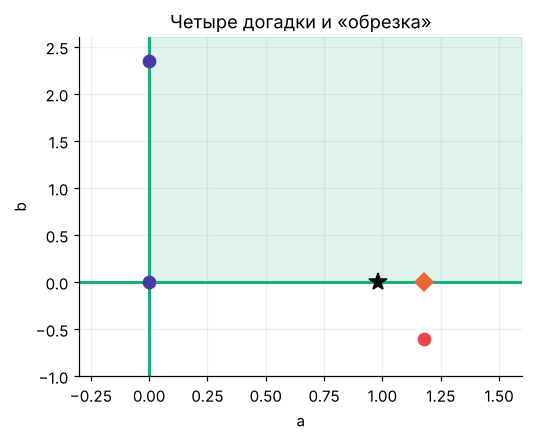

In [2]:
print("grad f(a, b) = (30a + 10b - 29.4, 10a + 4b - 9.4)")                 # суммы по данным из введения
names = {(): "не работает ни одно", (0, 1): "работают оба", (0,): "только a >= 0", (1,): "только b >= 0"}
for A, name in names.items():
    x, mu = taxi_guess(A)                                    # система с ограничениями A как равенствами
    ok_x = x.min() >= -1e-12                                 # допустимость: a >= 0, b >= 0
    ok_mu = all(mu[i] >= -1e-12 for i in A)                  # знак у работающих ограничений
    print(f"{name:20s}: (a, b) = {x.round(3) + 0.0}, mu = {mu.round(3) + 0.0}, x >= 0: {ok_x}, mu >= 0: {ok_mu}")   # + 0.0 убирает «-0.»
x_clip = np.array([taxi_guess(())[0][0], 0.0])               # «обрезка»: b заменили нулём, a оставили
print("обрезка (1.18, 0): grad f =", taxi_grad(x_clip).round(3), f"| f = {taxi_f(x_clip):.3f}, у ответа f = {taxi_f(taxi_guess((1,))[0]):.3f}")
print("в конспекте: ответ (0.98, 0), mu2 = 0.4; оба как равенства mu = (-29.4, -9.4); только a = 0: mu1 = -5.9")

fig, ax = plt.subplots(figsize=(5.2, 4))
draw_quadrant(ax)
for A, col in (((), RED), ((0, 1), VIOLET), ((0,), VIOLET), ((1,), INK)):
    ax.plot(*taxi_guess(A)[0], "*" if A == (1,) else "o", color=col, ms=12 if A == (1,) else 8)
ax.plot(*x_clip, "D", color=ORANGE, ms=8)                     # «обрезка»
ax.set(xlim=(-0.3, 1.6), ylim=(-1.0, 2.6), xlabel="a", ylabel="b", title="Четыре догадки и «обрезка»")
plt.show()

**Что видим.** Без ограничений $b=-0.60<0$. «Оба как равенства» и «только $a\ge0$» дают отрицательные множители. Ответ — $(0.98,\ 0)$ с $\mu_2=0.4$: у каждого ограничения одно из чисел $h_i$, $\mu_i$ равно нулю. У «обрезки» первая компонента градиента равна $6$ при неработающем $a\ge0$, и $f=0.724$ против $0.124$.

## (b) Активное множество: портфель руками

**Что проверяем.** Схема «угадай и проверь» из §3.1 находит ответ за две догадки. IPOPT даёт те же доли и те же множители со знаком минус.

**Что делает ячейка.** `portfolio_active(rho, A)` решает систему Лагранжа, где доли из `A` равны нулю. Ячейка делает две догадки при $\rho=12\,\%$: $\mathcal A=\varnothing$ и $\mathcal A=\{1\}$. После каждой проверяет $x\ge0$ и $\mu\ge0$. Номера активов в коде — с нуля, поэтому $\{1\}$ в конспекте — это `[0]` в коде.

A = []: x = [-0.2015  0.4981  0.4324  0.271 ], lam_rho = 0.3511, mu = []
   x >= 0: False,  mu >= 0: True
A = [1]: x = [0.     0.1414 0.5026 0.356 ], lam_rho = 0.4731, mu = [0.0082]
   x >= 0: True,  mu >= 0: True
в конспекте: догадка 1 — x1 = -0.2015 < 0; догадка 2 — x = (0, 0.1414, 0.5026, 0.3560), mu1 = 0.0082


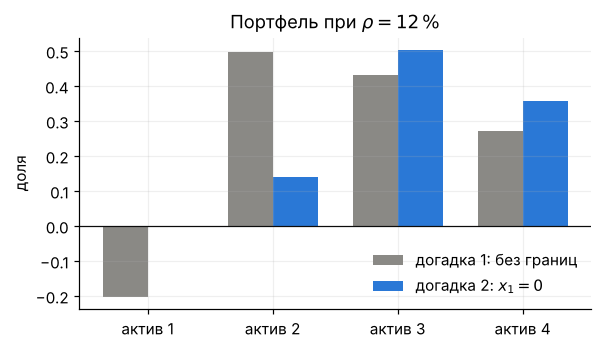

In [3]:
rho = 0.12
for A in ([], [0]):                                  # догадки: пусто, потом первая доля равна нулю
    x, lam1, lam_rho, mu = portfolio_active(rho, A)
    print(f"A = {[i + 1 for i in A]}: x = {x.round(4)}, lam_rho = {lam_rho:.4f}, mu = {mu.round(4)}")
    print(f"   x >= 0: {bool(x.min() >= -1e-12)},  mu >= 0: {bool(mu.size == 0 or mu.min() >= 0)}")
print("в конспекте: догадка 1 — x1 = -0.2015 < 0; догадка 2 — x = (0, 0.1414, 0.5026, 0.3560), mu1 = 0.0082")

x0 = portfolio_active(rho, [])[0]
x1 = portfolio_active(rho, [0])[0]
fig, ax = plt.subplots(figsize=(6, 3.2))
pos = np.arange(4)
ax.bar(pos - 0.18, x0, width=0.36, color=GRAY, label="догадка 1: без границ")
ax.bar(pos + 0.18, x1, width=0.36, color=BLUE, label="догадка 2: $x_1=0$")
ax.axhline(0, color=INK, lw=0.8)
ax.set(xticks=pos, xticklabels=[f"актив {i + 1}" for i in pos], ylabel="доля", title="Портфель при $\\rho=12\\,\\%$")
ax.legend()
plt.show()

**Что видим.** Первая догадка даёт $x_1=-0.20$ — проверка $x\ge0$ не проходит. Вторая догадка проходит обе проверки: доли неотрицательны, $\mu_1=0.0082\ge0$. Цена доходности $\lambda_\rho$ выросла с $0.351$ до $0.473$.

**Что делает ячейка.** Решает ту же задачу IPOPT через CasADi. Равенства идут в `g` с границами `lbg=ubg=0`, неравенства $x\ge0$ — в границы переменных `lbx=0`, `ubx=inf`. Множители равенств IPOPT возвращает в `lam_g`, множители границ — в `lam_x`.

In [4]:
xs = ca.SX.sym("x", 4)                                         # доли
nlp = {"x": xs,
       "f": 0.5 * ca.mtimes([xs.T, ca.DM(PF_SIGMA), xs]),       # риск
       "g": ca.vertcat(ca.sum1(xs) - 1,                         # весь капитал вложен
                       ca.dot(ca.DM(PF_R), xs) - rho)}          # доходность rho
solver = ca.nlpsol("pf", "ipopt", nlp, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
res = solver(x0=np.ones(4) / 4, lbx=0, ubx=ca.inf, lbg=0, ubg=0)
x_ip = np.array(res["x"]).ravel()
print("IPOPT: итераций", solver.stats()["iter_count"], "| x =", x_ip.round(4))
print("lam_g =", np.array(res["lam_g"]).ravel().round(4), "| наши -lambda =", -np.round([-0.0265, 0.4731], 4))
print("lam_x =", np.array(res["lam_x"]).ravel().round(4), "| наши -mu =", -np.round([0.0082, 0, 0, 0], 4))
print("в конспекте: 9 итераций, lam_x = (-0.0082, 0, 0, 0), lam_g = (0.0265, -0.4731)")

IPOPT: итераций 9 | x = [0.     0.1414 0.5026 0.356 ]
lam_g = [ 0.0265 -0.4731] | наши -lambda = [ 0.0265 -0.4731]
lam_x = [-0.0082 -0.     -0.     -0.    ] | наши -mu = [-0.0082 -0.     -0.     -0.    ]
в конспекте: 9 итераций, lam_x = (-0.0082, 0, 0, 0), lam_g = (0.0265, -0.4731)


**Что видим.** IPOPT приходит к тем же долям за 9 итераций. Его множители — наши со знаком минус: и у равенств, и у границ. Отрицательный `lam_x` значит активную нижнюю границу.

## (c) Уголок и гипербола: точки при $\mu_ih_i=\tau$

**Что проверяем.** Заменим $\mu_ih_i=0$ на $\mu_ih_i=\tau$ и возьмём ветвь с $\mu_i>0$, $h_i>0$. Точка задачи «такси» тогда лежит внутри четверти $a>0$, $b>0$. При уменьшении $\tau$ она приближается к ответу.

**Что делает ячейка.** Для $\tau=1,\ 0.1,\ 0.01,\ 0.001$ решает систему $\nabla f=(\mu_1,\mu_2)$, $\mu_1a=\tau$, $\mu_2b=\tau$ функцией `taxi_tau`. Корень она ищет там, где $a>0$ и $b>0$, — это и есть выбор ветви. Ячейка печатает точку, множители и расстояние до ответа и рисует расстояние от $\tau$.

tau = 1.0   : (a, b) = (0.7729, 0.7508), mu = (1.2939, 1.3319), до ответа 0.7789
tau = 0.1   : (a, b) = (0.9237, 0.1799), mu = (0.1083, 0.5560), до ответа 0.1885
tau = 0.01  : (a, b) = (0.9724, 0.0238), mu = (0.0103, 0.4193), до ответа 0.0250
tau = 0.001 : (a, b) = (0.9792, 0.0025), mu = (0.0010, 0.4020), до ответа 0.0026
в конспекте: при tau = 0.1 точка (0.924, 0.180), до ответа 0.19; при tau = 0.01 — 0.025; mu -> (0, 0.4)


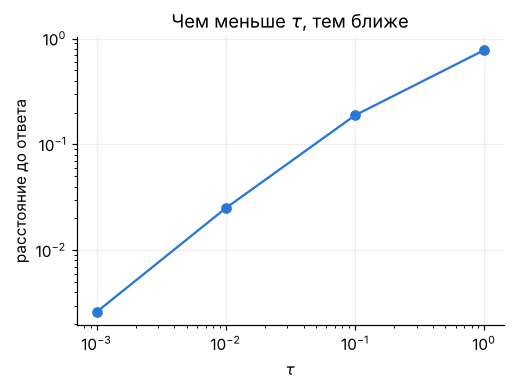

In [5]:
taus = [1.0, 0.1, 0.01, 0.001]
dist = []
x_star = taxi_guess((1,))[0]                                 # ответ (0.98, 0)
for tau in taus:
    x, mu = taxi_tau(tau)                                    # точка, где mu_i * h_i = tau
    dist.append(np.linalg.norm(x - x_star))
    print(f"tau = {tau:<6}: (a, b) = ({x[0]:.4f}, {x[1]:.4f}), mu = ({mu[0]:.4f}, {mu[1]:.4f}), до ответа {dist[-1]:.4f}")
print("в конспекте: при tau = 0.1 точка (0.924, 0.180), до ответа 0.19; при tau = 0.01 — 0.025; mu -> (0, 0.4)")

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.loglog(taus, dist, "o-", color=BLUE)
ax.set(xlabel="$\\tau$", ylabel="расстояние до ответа", title="Чем меньше $\\tau$, тем ближе")
plt.show()

**Что видим.** Все точки внутри: $a>0$ и $b>0$. Расстояние до ответа уменьшается примерно в 10 раз при каждом уменьшении $\tau$ в 10 раз. Множители стремятся к $(0,\ 0.4)$ — к множителям ответа. Каждая точка — решение системы из одних уравнений, её находит метод Ньютона. Это идея метода внутренней точки (лекция 12).

## (e) Подробности: перебор всех активных множеств портфеля

**Что делает ячейка.** Перебирает все активные множества из не больше чем двух границ при $\rho=12\,\%$. Три и четыре границы вместе с двумя равенствами — это 5–6 ограничений на 4 переменные, такие системы вырождены. Для каждого множества печатает, проходят ли проверки $x\ge0$ и $\mu\ge0$.

In [6]:
for k in range(3):
    for A in combinations(range(4), k):
        x, lam1, lam_rho, mu = portfolio_active(0.12, A)
        ok_x = x.min() >= -1e-12                                  # допустимость
        ok_mu = mu.size == 0 or mu.min() >= -1e-12                # знаки
        mark = "  <- ответ" if ok_x and ok_mu else ""
        print(f"A = {str([i + 1 for i in A]):8s} x >= 0: {str(ok_x):5s} mu >= 0: {str(ok_mu):5s}{mark}")

A = []       x >= 0: False mu >= 0: True 
A = [1]      x >= 0: True  mu >= 0: True   <- ответ
A = [2]      x >= 0: True  mu >= 0: False
A = [3]      x >= 0: False mu >= 0: False
A = [4]      x >= 0: False mu >= 0: False
A = [1, 2]   x >= 0: True  mu >= 0: False
A = [1, 3]   x >= 0: True  mu >= 0: False
A = [1, 4]   x >= 0: False mu >= 0: False
A = [2, 3]   x >= 0: True  mu >= 0: False
A = [2, 4]   x >= 0: False mu >= 0: False
A = [3, 4]   x >= 0: False mu >= 0: False


**Что видим.** Из 11 множеств обе проверки проходит одно — $\{1\}$. Схема §3.1 нашла его за две догадки, перебор проверяет 11.

## Шпаргалка

| Что | Формула | Где в конспекте |
|---|---|---|
| условия ККТ | $\nabla f-J_g^\top\lambda-J_h^\top\mu=0$, $g=0$, $h\ge0$, $\mu\ge0$, $\mu_ih_i=0$ | §2.2 |
| активное множество | $\mathcal A(x)=\{i:\ h_i(x)=0\}$ | §2.2 |
| «угадай и проверь» | $h_i\ge0$ вне $\mathcal A$, $\mu_i\ge0$ в $\mathcal A$ | §3.1 |
| сглаживание | $\mu h=\tau$ вместо $\mu h=0$ | §4 |

**Три вещи, которые легко перепутать.**

1. Неактивное ограничение — это $\mu_i=0$, а не «ограничение нарушено». Нарушенное ограничение — это $h_i<0$.
2. На границе может быть и $\mu_i=0$: тогда равны нулю оба числа (упражнение 10.1(б)).
3. Знак множителей у солверов свой: IPOPT возвращает наши $\mu$ и $\lambda$ со знаком минус.